In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler ,minmax_scale

In [25]:
df = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\sales_orders.csv')

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 540000 entries, 0 to 539999
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sales_order_id      540000 non-null  object 
 1   order_date          540000 non-null  object 
 2   branch_id           540000 non-null  object 
 3   customer_id         437039 non-null  object 
 4   sales_channel       540000 non-null  object 
 5   payment_method      540000 non-null  object 
 6   items_count         540000 non-null  int64  
 7   gross_EGP           540000 non-null  float64
 8   discount_EGP        540000 non-null  float64
 9   net_before_tax_EGP  540000 non-null  float64
 10  tax_EGP             540000 non-null  float64
 11  paid_total_EGP      540000 non-null  float64
 12  status              540000 non-null  object 
dtypes: float64(5), int64(1), object(7)
memory usage: 53.6+ MB


In [27]:
df['order_date'] = pd.to_datetime(df['order_date'],format='%Y-%m-%d')

In [28]:
df.dropna(inplace=True)

In [29]:
RFM = pd.DataFrame()

In [30]:
snapshot_date = df['order_date'].max() + pd.Timedelta(days=30)


RFM = df.groupby('customer_id').agg(
    recency=('order_date', lambda x: (snapshot_date - x.max()).days),
    frequency=('sales_order_id', 'nunique'),
    monetary=('paid_total_EGP', 'sum')
).reset_index()

In [31]:
RFM.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74660 entries, 0 to 74659
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   customer_id  74660 non-null  object 
 1   recency      74660 non-null  int64  
 2   frequency    74660 non-null  int64  
 3   monetary     74660 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 2.3+ MB


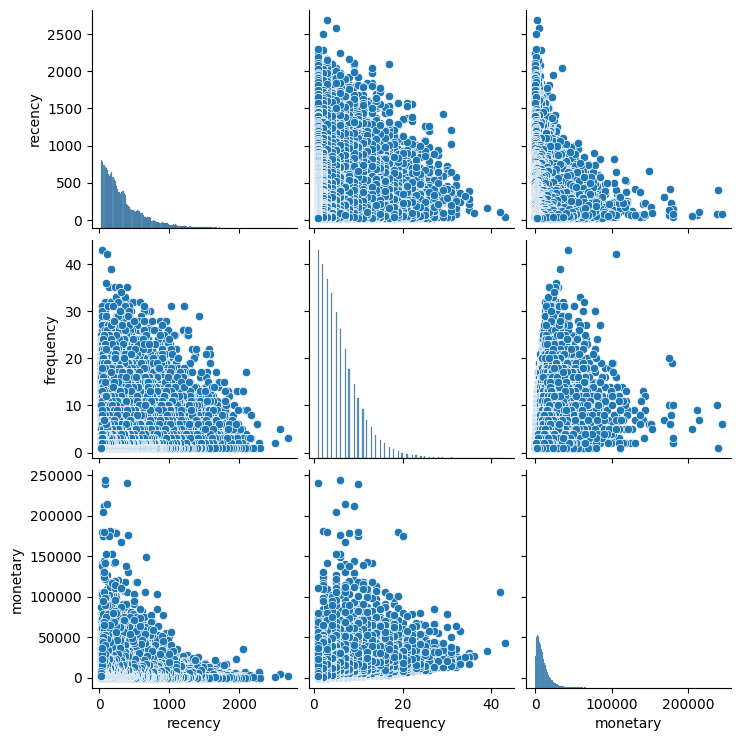

In [32]:
sns.pairplot(RFM.drop(columns=['customer_id']))

In [33]:
X = RFM.drop(columns=['customer_id'])

In [34]:
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

In [35]:
X_train_scaled = np.log1p(X_train)
X_test_scaled = np.log1p(X_test)

In [36]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_scaled)
X_test_scaled = scaler.transform(X_test_scaled)

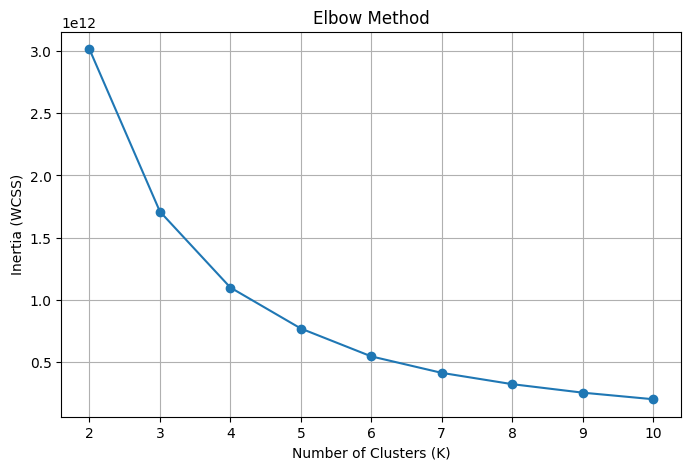

In [37]:
inertias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_train)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')
plt.xticks(K_range)
plt.grid()
plt.show()

In [38]:
kmeans = KMeans(n_clusters=5)
labels = kmeans.fit_predict(X_train_scaled)

In [39]:
X_train = X_train.copy()
X_train['cluster'] = labels

In [40]:
cluster_analysis = X_train.groupby('cluster').agg(
    customers=('recency', 'count'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean')
).round(2)

print(cluster_analysis)

         customers  avg_recency  avg_frequency  avg_monetary
cluster                                                     
0            16106       508.09           4.24       7221.35
1            13762       400.70          10.64      16791.55
2             7798       557.08           1.51       1487.81
3            12979        99.65           7.92      16768.40
4             9083       120.21           2.26       4665.88


In [41]:
segment_names = {
    0: 'Lost / Inactive Customers',
    1: 'High-Value Loyal Customers',
    2: 'Regular Customers',
    3: 'VIP / Premium Customers',
    4: 'Potential Loyal Customers'
}

X_train['segment'] = X_train['cluster'].map(segment_names)

Customer Segments – Purchasing Behavior
Segment 0: Lost / Inactive Customers
These customers have not made a purchase for a long time and demonstrate relatively low purchasing frequency and spending. Their engagement with the business has declined significantly, making them potential targets for reactivation campaigns.
Segment 1: High-Value Loyal Customers
These customers show very weak purchasing engagement, with infrequent purchases and the lowest spending contribution. They have not demonstrated the characteristics of loyal or high-value customers and are more likely to be inactive or disengaged.
Segment 2: Regular Customers
These customers demonstrate consistent purchasing behavior, with recent transactions and relatively high purchasing frequency. They represent an active customer base that contributes significantly to business revenue and is worth retaining.
Segment 3: VIP / Premium Customers
These customers have relatively recent purchasing activity but demonstrate limited purchasing frequency and moderate spending. They may have the potential to become more engaged customers through personalized offers and targeted marketing.
Segment 4: Potential Loyal Customers
These customers have demonstrated strong historical purchasing habits and high spending contributions. However, their recent engagement has declined, making them good candidates for re-engagement campaigns to restore their previous purchasing activity.

In [42]:
import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Existing fitted models
rfm_pipeline = Pipeline([
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scaler', scaler),
    ('kmeans', kmeans)
])

# Save the complete pipeline
joblib.dump(rfm_pipeline, 'rfm_segmentation_pipeline.joblib')

['rfm_segmentation_pipeline.joblib']

In [43]:
def calculate_rfm(transactions):

    transactions = transactions.copy()
    transactions['order_date'] = pd.to_datetime(
        transactions['order_date']
    )

    snapshot_date = (
        transactions['order_date'].max()
        + pd.Timedelta(days=30)
    )

    rfm = transactions.groupby('customer_id').agg(
        recency=('order_date', lambda x: (snapshot_date - x.max()).days),
        frequency=('sales_order_id', 'nunique'),
        monetary=('paid_total_EGP', 'sum')
    )

    return rfm[['recency', 'frequency', 'monetary']]

In [44]:
new_transactions = df.copy()

In [45]:
segment_names = {
    0: 'Lost / Inactive Customers',
    1: 'High-Value Loyal Customers',
    2: 'Regular Customers',
    3: 'VIP / Premium Customers',
    4: 'Potential Loyal Customers'
}

loaded_pipeline = joblib.load('rfm_segmentation_pipeline.joblib')

new_rfm = calculate_rfm(new_transactions)

predictions = loaded_pipeline.predict(new_rfm)

results = new_rfm.copy()
results['cluster'] = predictions
results['segment'] = results['cluster'].map(segment_names)

results.head()

,recency,frequency,monetary,cluster,segment
customer_id,,,,,
C0000001,229,26,13110.73,1,High-Value Loyal Customers
C0000002,114,27,20252.05,1,High-Value Loyal Customers
C0000003,285,21,19963.11,1,High-Value Loyal Customers
C0000004,125,20,23267.67,3,VIP / Premium Customers
C0000005,221,21,14498.52,1,High-Value Loyal Customers


In [46]:
results.to_csv('rfm_segmented_results.csv', index=True)

In [47]:
sales_orders = pd.read_csv(r'D:\HVIA\New folder\Cottonil_project\COTTONIL\data\sales_orders.csv')
rfm_segmented_results = pd.read_csv('rfm_segmented_results.csv')

In [52]:

# Merge sales orders with RFM segments
merged_df = sales_orders.merge(
    rfm_segmented_results[['customer_id', 'segment']],
    on='customer_id',
    how='inner'
)

# Keep the required customer segments
filtered_df = merged_df[
    merged_df['segment'].isin([
        'Regular Customers',
        'High-Value Loyal Customers'
    ])
]

# Calculate customer-level statistics
customer_analysis = filtered_df.groupby(
    ['segment', 'customer_id']
).agg(
    total_orders=('sales_order_id', 'nunique'),
    unique_branches=('branch_id', 'nunique')
).reset_index()

# Aggregate branch statistics by segment
branch_analysis = customer_analysis.groupby('segment')[
    'unique_branches'
].agg(
    median='median',
    min='min',
    max='max'
)

# Calculate payment method and channel modes by segment
payment_mode = filtered_df.groupby('segment')['payment_method'].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else None
)

channel_mode = filtered_df.groupby('segment')['sales_channel'].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else None
)

# Combine all analyses
final_analysis = branch_analysis.join(
    payment_mode.rename('most_used_payment_method')
).join(
    channel_mode.rename('most_used_channel')
)

final_analysis


,median,min,max,most_used_payment_method,most_used_channel
segment,,,,,
High-Value Loyal Customers,9.0,2,35,Cash,Retail POS
Regular Customers,1.0,1,6,Cash,Retail POS


In [53]:

import plotly.express as px

# Merge sales orders with RFM segments
merged_df = sales_orders.merge(
    rfm_segmented_results[['customer_id', 'segment']],
    on='customer_id',
    how='inner'
)

# Calculate total items per customer within each segment
customer_items = merged_df.groupby(
    ['segment', 'customer_id']
)['items_count'].sum().reset_index()

# Calculate mean and standard deviation per segment
segment_items = customer_items.groupby('segment')['items_count'].agg(
    mean='mean',
    std='std'
).reset_index()

# Interactive bar plot with standard deviation
fig = px.bar(
    segment_items,
    x='segment',
    y='mean',
    error_y='std',
    text_auto='.2f',
    title='Average Items Count per Customer Across Segments',
    labels={
        'segment': 'Customer Segment',
        'mean': 'Average Items Count',
        'std': 'Standard Deviation'
    },
    hover_data={
        'mean': ':.2f',
        'std': ':.2f'
    }
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Customer Segment',
    yaxis_title='Average Items Count',
    showlegend=False
)

fig.show()
